# DATA 501 — Module 7 - 9 Project
## Own the Database: Ride Knox Goes Upstream for Good

**Name:** *Zaharia Selman*

**NetID:** *zselman*

---

## Part 0 — Setup & the Working Copy

In [1]:
# --- PROVIDED SETUP from Module 9 assignment ---
import os
import shutil
import sqlite3
import time

import pandas as pd
import matplotlib.pyplot as plt

SOURCE = "ride_knox_v2.db"

if os.path.exists(SOURCE):
    os.remove(SOURCE)

con = sqlite3.connect(SOURCE)
con.isolation_level = None     # BEGIN / COMMIT / ROLLBACK behave as written


# def run(sql):
#     """Execute ONE statement. Returns rows affected."""
#     return con.execute(sql).rowcount


def try_run(sql):
    """For statements you EXPECT to be refused: prints the database's
    complaint instead of stopping the notebook."""
    try:
        n = con.execute(sql).rowcount
        return f"ACCEPTED ({n} rows) — is that what you expected?"
    except sqlite3.Error as e:
        return f"REFUSED -> {e}"


def timed(sql, params=(), repeat=5):
    """Run a query a few times; return the fastest run, in milliseconds."""
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        con.execute(sql, params).fetchall()
        best = min(best, time.perf_counter() - t0)
    return round(best * 1000, 1)


def db_size_mb():
    return round(os.path.getsize(SOURCE) / 1_048_576, 1)


print("fresh working copy:", SOURCE, "|", db_size_mb(), "MB")

fresh working copy: ride_knox_v2.db | 0.0 MB


## Part A - Schema design & the data dictionary 

In [2]:
## All tables in schema created in this code block
schema_file_path = 'sql/schema.sql'

# Read schema.sql
with open(schema_file_path, 'r') as f: # AI here
    sql_schema = f.read()

# Execute code to build tables
con.executescript(sql_schema)

# Save
con.commit()
# con.rollback()

*Please refer to DATA-DICTIONARY.md and sql/schema.sql for every table, column, constraint, and design decision/rationale for the database.*

## Part B & C - Load, Reconcile the History, and The July 2026 Drill

In [3]:
# All data loaded into the tables are in this code block: Used AI here but I understand and checked thoroughly all of the steps 
# because it incorporates code from previous modules

# Definition for my data pipeline mapping: { 'staging_table_name': 'raw_file_path' }
data_pipeline = {
    'staging_stations_v2': 'stations_2026.xlsx',
    'staging_trips_v2': 'trips_2025.csv',
    'staging_trips_26': 'trips_2026_h1.csv',
    'staging_trips_26_07': 'trips_2026_07.csv'
}


# Automated Data Loader Loop
for table_name, file_path in data_pipeline.items():
    print(f"Loading {file_path} into {table_name}...")
    
    # Dynamically select loader depending on file type
    if file_path.endswith('.csv'):
        df = pd.read_csv(file_path)
    elif file_path.endswith(('.xlsx', '.xls')):
        df = pd.read_excel(file_path)
    else:
        print(f"⚠️ Unsupported file type for {file_path}")
        continue
        
    # Append the raw data straight into the designated staging table
    df.to_sql(table_name, con, if_exists='append', index=False)

con.commit()
print("🎉 All raw data files successfully pushed to staging tables!")

Loading stations_2026.xlsx into staging_stations_v2...
Loading trips_2025.csv into staging_trips_v2...
Loading trips_2026_h1.csv into staging_trips_26...
Loading trips_2026_07.csv into staging_trips_26_07...
🎉 All raw data files successfully pushed to staging tables!


In [4]:
# Load all staging tables before loading data into production tables
load_file_path = 'sql/load.sql'

with open(load_file_path, 'r') as f:
    load_script = f.read()

con.executescript(load_script)

# con.rollback()

In [5]:
# Reconciliation file
recon_file_path = 'sql/reconciliation.sql'

with open(recon_file_path, 'r') as f:
    recon_script = f.read()

queries = recon_script.split(";") #AI Here

 # Iterate and display what's in the reconciliation script
for i, query in enumerate(queries, 1):
    
    try:
        print(pd.read_sql(query, con))
    except Exception as e:
        print(f"Error executing statement: {e}")

Error executing statement: 'NoneType' object is not iterable
Empty DataFrame
Columns: [table, rowid, parent, fkid]
Index: []
   stations
0        25
   station_expansions
0                   3
   rider_types
0            3
   trips_2025
0      249737
   trips_2026
0      136991
   trips_07_2026
0          32865
   trips_total
0       418486
Error executing statement: 'NoneType' object is not iterable


*The total trips loaded into trips_v2 is less than the sum of all the data from the trip's files (419,593 trips) because of the 1,107 trip duplicates that got rejected at the door.*

In [6]:
# Helpful Python Tool: Python tracks every line of code executed in a session. 
# Run this command in a new cell to print everything you've run so far
# %history -n 1-500

*Data from every raw table from Ride Knox is now in a table that has appropriate constraints for every time this notebook is run. Also, please refer to DATA-DICTIONARY.md for a written inspection log and a decision, with rationale, for every anomaly in working with the newest export of data (July 2026 trips).*

## Part D - The Reporting Layer

In [7]:
# Created a view that captures my definition of a trip that belongs in reports 
view_file_path = 'sql/views.sql'

with open(view_file_path, 'r') as f: # AI here
    sql_view = f.read()

con.executescript(sql_view)

*See DATA-DICTIONARY.md for the justification for this view.*

In [8]:
# # Reports (anniversary and capacity) using view created in previous code
report_file_path = 'sql/reports.sql'

with open(report_file_path, 'r') as f:
    report_script = f.read()

con.executescript(report_script)

queries = report_script.split(";")

for i, query in enumerate(queries, 1):
    
    try:
        print(f"\nReport: {pd.read_sql(query, con)}")
    except Exception as e:
        print(f"Error executing statement: {e}")

Error executing statement: 'NoneType' object is not iterable

Report:    foreign_keys
0             1

Report: Empty DataFrame
Columns: [table, rowid, parent, fkid]
Index: []

Report:    year     rider  trips  avg_min  classic_bike  electric_bike  \
0  2025    casual   8974     22.8          5524           3450   
1  2025    member  17578     13.5         10844           6734   
2  2026    casual   7504     22.9          4483           2902   
3  2026  day pass   4737     24.3          2861           1801   
4  2026    member  19492     13.5         11855           7493   

   rider_share_pct  percentage_denominator  
0            33.80                   26552  
1            66.20                   26552  
2            23.65                   31733  
3            14.93                   31733  
4            61.43                   31733  

Report:    date_label     rider  trips  avg_min  classic_bike  electric_bike  \
0     2025-03    casual   8444     22.9          5200           3244

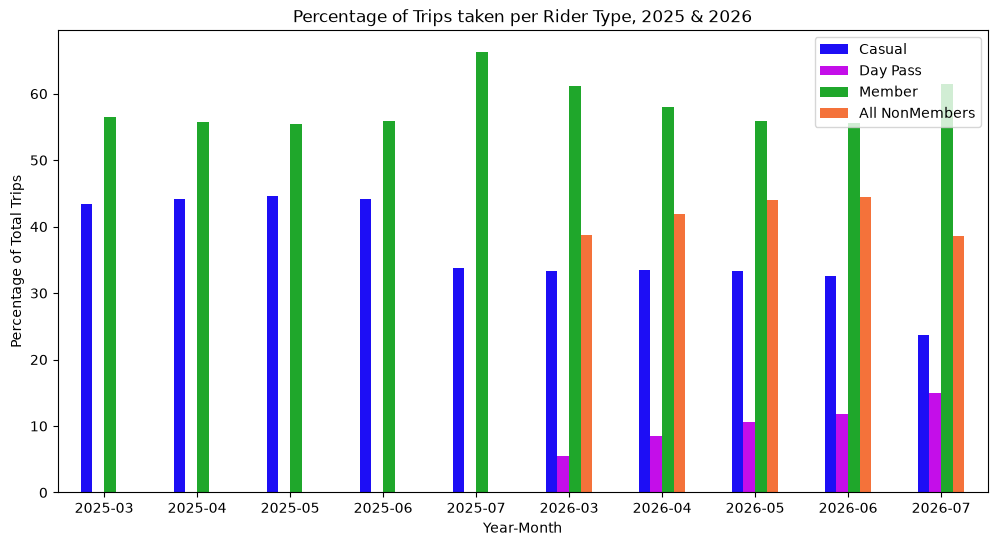

In [9]:
## Charts saved in charts/ folder

anniversary = pd.read_sql("""
SELECT 
strftime('%Y-%m', start_time) AS date_label, rider_type AS rider, 
COUNT(*) AS trips, ROUND(AVG(duration_min), 1) AS avg_min,
SUM(CASE WHEN bike_type = 'classic' THEN 1 ELSE 0 END) AS classic_bike,
SUM(CASE WHEN bike_type = 'electric' THEN 1 ELSE 0 END) AS electric_bike,
ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))),2) AS rider_share_pct,
SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))) AS percentage_denominator
FROM clean_trips
WHERE (start_time >= '2025-03-01'
AND start_time < '2025-08-01')
OR (start_time >= '2026-03-01'
AND start_time < '2026-08-01')
GROUP BY strftime('%Y', start_time), strftime('%m', start_time), rider_type
""", con)

wide = anniversary.pivot(index=["date_label"], columns="rider", values="rider_share_pct")
wide["Total Casual & Day Pass"] = wide["casual"] + wide["day pass"]
wide.sort_index(ascending=True, inplace=True) #start from the lowest value (x-axis) rather than the reverse

ax = wide.plot(kind="bar", stacked=False, color=["#1d0ef5", "#c40ee9", "#14a320f3", "#f46b30f3"], figsize=(12, 6))

plt.title("Percentage of Trips taken per Rider Type, 2025 & 2026")
plt.xlabel("Year-Month"); plt.ylabel("Percentage of Total Trips")
plt.xticks(rotation=0)
plt.legend(["Casual", "Day Pass", "Member", "All NonMembers"])
#list(map(ax.bar_label, ax.containers)) #AI Here: Show values above their bars

plt.savefig("charts/riders_anniversary_report.png", dpi=150, bbox_inches="tight")

*Figure 1 Caption: Comparison between the percentage of all trips taken by each rider type in July 2025 vs July 2026. All rider types show a decline (except Day Pass riders which didn't exist in 2025). However, adding Casual and Day Pass riders together (as non-members; 38.58%) in 2026 exceeds the percentage of Casual riders alone, showing the success of the Day Pass rider option offered in 2026. Please see DATA-DICTIONARY.md for the denominators for these percentages.*

In [10]:
## Parameterized QUERY
# Capacity verdict for S06, S08, S25, S23, S24
# AI Here, but updated to reflect my understanding of the code
query = """
SELECT 
    b.station_id,
    
	-- 1. Get 2025 Trips and calculate 2025 Pressure (using COALESCE for before expansion dock counts)
    SUM(CASE WHEN strftime('%Y', t.start_time) = ?1 THEN 1 ELSE 0 END) AS trips_Y1,
    COALESCE(e.docks_before, b.docks) AS docks_Y1, --AI Here
    ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = ?1 THEN 1 ELSE 0 END) * 1.0 / COALESCE(e.docks_before, b.docks), 2) AS Month_Y1_pressure,

    -- 2. Get 2026 Trips and calculate 2026 Pressure (after expansion dock counts are already currently stored in stations)
    SUM(CASE WHEN strftime('%Y', t.start_time) = ?2 THEN 1 ELSE 0 END) AS trips_Y2,
    b.docks AS docks_Y2, --2026 which is current
    ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = ?2 THEN 1 ELSE 0 END) * 1.0 / b.docks, 2) AS Month_Y2_pressure

FROM stations_v2 b
-- Look up 2025 before dock counts if they exist
LEFT JOIN stations_docks e ON b.station_id = e.station_id
-- Join all trip records that occurred in July of either year
LEFT JOIN clean_trips t ON b.station_id = t.start_station_id 
    AND strftime('%m', t.start_time) = ?3

-- Filter down to just 5 target stations
WHERE b.station_id IN (?4, ?5, ?6, ?7, ?8)
GROUP BY b.station_id
ORDER BY b.station_id;
"""
## Query used in 2 Different Calls as Examples
pd.read_sql(query, con, params=('2025', '2026', '03', 'S06', 'S08', 'S23', 'S24', 'S25')) #Comparison of the dock pressure for March 2025 vs March 2026 (the month the Day Pass started to be offered)
pd.read_sql(query, con, params=('2025', '2026', '07', 'S06', 'S08', 'S23', 'S24', 'S25')) #Year 1 (2025), Year 2 (2026), Month (July (07))that you want to compare between (requested in project)

,station_id,trips_Y1,docks_Y1,Month_Y1_pressure,trips_Y2,docks_Y2,Month_Y2_pressure
0,S06,2746,24,114.42,2528,32,79.00
1,S08,2546,24,106.08,2408,32,75.25
2,S23,207,12,17.25,452,12,37.67
3,S24,215,10,21.50,268,10,26.80
4,S25,0,0,NaN,2124,16,132.75


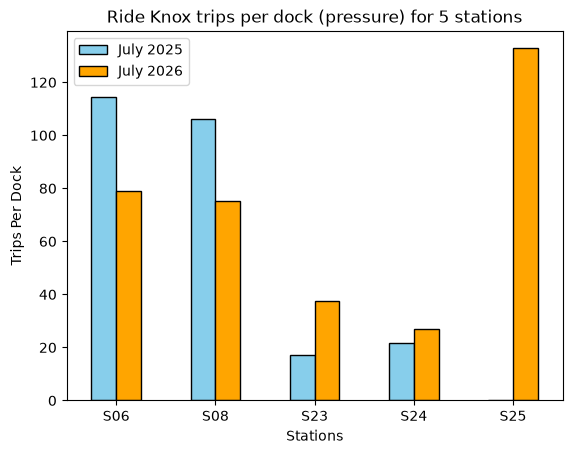

In [11]:
## Charts saved in charts/ folder

per_dock = pd.read_sql(query, con, params=('2025', '2026', '07', 'S06', 'S08', 'S23', 'S24', 'S25'))

per_dock.set_index('station_id', inplace=True)
per_dock.sort_index(ascending=True, inplace=True)

per_dock[["Month_Y1_pressure", "Month_Y2_pressure"]].plot(kind = 'bar', color=['skyblue', 'orange'], edgecolor='black')
plt.title("Ride Knox trips per dock (pressure) for 5 stations")
plt.xlabel("Stations"); plt.ylabel("Trips Per Dock")
plt.xticks(rotation=0)
plt.legend(["July 2025", "July 2026"])

plt.savefig("charts/dock_pressure.png", dpi=150, bbox_inches="tight")


*Figure 2 Caption: Comparison of the trips per dock per station that leadership has acted (S06, S08, S23, S24, and S25) from July 2025 vs July 2026.*

*Please reference DATA-DICTIONARY.md for interpretation of these reports/figures.*

## Part E - Make It Fast, Prove It

In [12]:
## Derivation of my anniversary query since Views cannot be indexed

print(pd.read_sql("""
EXPLAIN QUERY PLAN
SELECT strftime('%Y-%m', start_time) AS date_label, rider_type AS rider, COUNT(*) AS trips, SUM(CASE WHEN bike_type = 'classic' THEN 1 ELSE 0 END)
AS classic_bike, SUM(CASE WHEN bike_type = 'electric' THEN 1 ELSE 0 END) AS electric_bike,
ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))),2) AS rider_share_pct,
SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))) AS percentage_denominator,
end_time, end_station_id
FROM trips_v2
WHERE end_station_id IS NOT NULL 
AND ((start_time >= '2025-03-01' AND start_time < '2025-08-01') OR (start_time >= '2026-03-01' AND start_time < '2026-08-01'))
AND end_time IS NOT NULL
AND (julianday(end_time) - julianday(start_time)) * 1440 BETWEEN 1 AND 1440
GROUP BY rider_type
""", con))

anniv_query = """SELECT strftime('%Y-%m', start_time) AS date_label, rider_type AS rider, COUNT(*) AS trips, SUM(CASE WHEN bike_type = 'classic' THEN 1 ELSE 0 END)
AS classic_bike, SUM(CASE WHEN bike_type = 'electric' THEN 1 ELSE 0 END) AS electric_bike,
ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))),2) AS rider_share_pct,
SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))) AS percentage_denominator,
end_time, end_station_id
FROM trips_v2
WHERE end_station_id IS NOT NULL 
AND ((start_time >= '2025-03-01' AND start_time < '2025-08-01') OR (start_time >= '2026-03-01' AND start_time < '2026-08-01'))
AND end_time IS NOT NULL
AND (julianday(end_time) - julianday(start_time)) * 1440 BETWEEN 1 AND 1440
GROUP BY rider_type"""

print(f"\nTime (ms): {timed(anniv_query)}")
print(f"\nSize: {db_size_mb()}")

    id  parent  notused                        detail
0    4       0        0       CO-ROUTINE (subquery-2)
1   11       4      216                 SCAN trips_v2
2   33       4        0  USE TEMP B-TREE FOR GROUP BY
3   97       4        0  USE TEMP B-TREE FOR ORDER BY
4  122       0       82             SCAN (subquery-2)

Time (ms): 640.9

Size: 81.2


In [13]:
print(pd.read_sql("""
EXPLAIN QUERY PLAN
SELECT b.station_id, SUM(CASE WHEN strftime('%Y', t.start_time) = '2025' THEN 1 ELSE 0 END) AS trips_2025,
COALESCE(e.docks_before, b.docks) AS docks_2025, ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = '2025' THEN 1 ELSE 0 END) * 1.0 / COALESCE(e.docks_before, b.docks), 2) AS July_2025_pressure,
SUM(CASE WHEN strftime('%Y', t.start_time) = '2026' THEN 1 ELSE 0 END) AS trips_2026, b.docks AS docks_2026,
ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = '2026' THEN 1 ELSE 0 END) * 1.0 / b.docks, 2) AS July_2026_pressure
FROM stations_v2 b
LEFT JOIN stations_docks e ON b.station_id = e.station_id
LEFT JOIN clean_trips t ON b.station_id = t.start_station_id AND strftime('%m', t.start_time) = '07'
WHERE b.station_id IN ('S06', 'S08', 'S23', 'S24', 'S25')
GROUP BY b.station_id
""", con))

pressure_query = "SELECT b.station_id, SUM(CASE WHEN strftime('%Y', t.start_time) = '2025' THEN 1 ELSE 0 END) AS trips_2025, " \
"COALESCE(e.docks_before, b.docks) AS docks_2025, ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = '2025' THEN 1 ELSE 0 END) * 1.0 / COALESCE(e.docks_before, b.docks), 2) AS July_2025_pressure, " \
"SUM(CASE WHEN strftime('%Y', t.start_time) = '2026' THEN 1 ELSE 0 END) AS trips_2026, b.docks AS docks_2026, " \
"ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = '2026' THEN 1 ELSE 0 END) * 1.0 / b.docks, 2) AS July_2026_pressure " \
"FROM stations_v2 b " \
"LEFT JOIN stations_docks e ON b.station_id = e.station_id " \
"LEFT JOIN clean_trips t ON b.station_id = t.start_station_id AND strftime('%m', t.start_time) = '07' " \
"WHERE b.station_id IN ('S06', 'S08', 'S23', 'S24', 'S25') " \
"GROUP BY b.station_id"

print(f"\nTime (ms): {timed(pressure_query)}")
print(f"\nSize: {db_size_mb()}")

   id  parent  notused                                             detail
0   9       0       69  SEARCH b USING INDEX sqlite_autoindex_stations...
1  37       0      216                                   SCAN e LEFT-JOIN
2  75       0       53  SEARCH trips_v2 USING AUTOMATIC PARTIAL COVERI...

Time (ms): 761.4

Size: 81.2


In [14]:
## Justified Index

index_file_path = 'sql/indexes.sql'

with open(index_file_path, 'r') as f:
    sql_index = f.read()

con.executescript(sql_index)

In [15]:
# Rerun the plan and timing for both "report" queries

# Force SQL to use the index I created
print(pd.read_sql("""
EXPLAIN QUERY PLAN
SELECT strftime('%Y-%m', start_time) AS date_label, rider_type AS rider, COUNT(*) AS trips, SUM(CASE WHEN bike_type = 'classic' THEN 1 ELSE 0 END)
AS classic_bike, SUM(CASE WHEN bike_type = 'electric' THEN 1 ELSE 0 END) AS electric_bike,
ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))),2) AS rider_share_pct,
SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))) AS percentage_denominator,
end_time, end_station_id
FROM trips_v2 INDEXED BY idx_trip_anniversary
WHERE end_station_id IS NOT NULL 
AND ((start_time >= '2025-03-01' AND start_time < '2025-08-01') OR (start_time >= '2026-03-01' AND start_time < '2026-08-01'))
AND end_time IS NOT NULL
AND (julianday(end_time) - julianday(start_time)) * 1440 BETWEEN 1 AND 1440
GROUP BY rider_type
""", con))

anniv_query = """SELECT strftime('%Y-%m', start_time) AS date_label, 
rider_type AS rider, COUNT(*) AS trips, SUM(CASE WHEN bike_type = 'classic' THEN 1 ELSE 0 END)
AS classic_bike, SUM(CASE WHEN bike_type = 'electric' THEN 1 ELSE 0 END) AS electric_bike,
ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))),2) AS rider_share_pct,
SUM(COUNT(*)) OVER(PARTITION BY (strftime('%Y', start_time)), (strftime('%m', start_time))) AS percentage_denominator,
end_time, end_station_id
FROM trips_v2 INDEXED BY idx_trip_anniversary
WHERE end_station_id IS NOT NULL 
AND ((start_time >= '2025-03-01' AND start_time < '2025-08-01') OR (start_time >= '2026-03-01' AND start_time < '2026-08-01'))
AND end_time IS NOT NULL
AND (julianday(end_time) - julianday(start_time)) * 1440 BETWEEN 1 AND 1440
GROUP BY rider_type"""

print(f"\nAnniversary Time (ms): {timed(anniv_query)}")
print(f"\nAnniversary Size: {db_size_mb()}")

# Force SQL to use my index, instead of the automatic ones from the JOINs
print(pd.read_sql("""
EXPLAIN QUERY PLAN
SELECT b.station_id, SUM(CASE WHEN strftime('%Y', t.start_time) = '2025' THEN 1 ELSE 0 END) AS trips_2025,
COALESCE(e.docks_before, b.docks) AS docks_2025, ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = '2025' THEN 1 ELSE 0 END) * 1.0 / COALESCE(e.docks_before, b.docks), 2) AS July_2025_pressure,
SUM(CASE WHEN strftime('%Y', t.start_time) = '2026' THEN 1 ELSE 0 END) AS trips_2026, b.docks AS docks_2026,
ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = '2026' THEN 1 ELSE 0 END) * 1.0 / b.docks, 2) AS July_2026_pressure
FROM stations_v2 b INDEXED BY idx_trip_dock_press
LEFT JOIN stations_docks e ON b.station_id = e.station_id
LEFT JOIN clean_trips t ON b.station_id = t.start_station_id AND strftime('%m', t.start_time) = '07'
WHERE b.station_id IN ('S06', 'S08', 'S23', 'S24', 'S25')
GROUP BY b.station_id
""", con))

pressure_query = "SELECT b.station_id, SUM(CASE WHEN strftime('%Y', t.start_time) = '2025' THEN 1 ELSE 0 END) AS trips_2025, " \
"COALESCE(e.docks_before, b.docks) AS docks_2025, ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = '2025' THEN 1 ELSE 0 END) * 1.0 / COALESCE(e.docks_before, b.docks), 2) AS July_2025_pressure, " \
"SUM(CASE WHEN strftime('%Y', t.start_time) = '2026' THEN 1 ELSE 0 END) AS trips_2026, b.docks AS docks_2026, " \
"ROUND(SUM(CASE WHEN strftime('%Y', t.start_time) = '2026' THEN 1 ELSE 0 END) * 1.0 / b.docks, 2) AS July_2026_pressure " \
"FROM stations_v2 b INDEXED BY idx_trip_dock_press " \
"LEFT JOIN stations_docks e ON b.station_id = e.station_id " \
"LEFT JOIN clean_trips t ON b.station_id = t.start_station_id AND strftime('%m', t.start_time) = '07' " \
"WHERE b.station_id IN ('S06', 'S08', 'S23', 'S24', 'S25') " \
"GROUP BY b.station_id"

print(f"\nDock Pressure Time (ms): {timed(pressure_query)}")
print(f"\nDock Pressure Size: {db_size_mb()}")

    id  parent  notused                                             detail
0    4       0        0                            CO-ROUTINE (subquery-2)
1   13       4        0                                     MULTI-INDEX OR
2   14      13        0                                            INDEX 1
3   21      14      164  SEARCH trips_v2 USING INDEX idx_trip_anniversa...
4   26      13        0                                            INDEX 2
5   33      26      164  SEARCH trips_v2 USING INDEX idx_trip_anniversa...
6   51       4        0                       USE TEMP B-TREE FOR GROUP BY
7  115       4        0                       USE TEMP B-TREE FOR ORDER BY
8  140       0       82                                  SCAN (subquery-2)

Anniversary Time (ms): 627.3

Anniversary Size: 94.0
   id  parent  notused                                             detail
0   9       0       85  SEARCH b USING INDEX idx_trip_dock_press (stat...
1  46       0       53  SEARCH e USING AUTOMATIC

*In this section I indexed by the station_id, end_station_id, start_time, and end_time columns. See DATA-DICTIONARY.md for my justification of these columns. I deliberately did not index by the rider_type or bike_type column in the anniversary query or start_time in the dock pressure query because rider_type only has three values and bike_type only has two values so much won't be eliminated from the searching time. Also, start_time is not filtered, joined, or ordered by in this query.*

## Part F - The Memo

**TO:** Director of Operations

**FROM:** Zaharia Selman, Ride Knox Data Scientist

**DATE:** September 21, 2026

**SUBJECT:** Ride Knox Goes Upstream for Good

---

## Bottom Line

*After investigating the one-year anniversary of the price increase, the Day Pass does seem to have brought casual riders back and the dock expansion and new station fix the campus crunch.*


## Evidence

- The Anniversary Verdict:

Trips taken by casual riders decreased steeply by 30.03% from July 2025 (made up 33.8% of total trips (26,552) in July) vs July 2026 (made up 23.65% of total trips (31,733) in July).

The decline in trips taken by member riders was less steep (7.21%) from July 2025 (made up 66.2% of total trips (26,552)) vs July 2026 (made up 61.43% of total trips (31,733)).

The average duration (in minutes) for casual (M=22.9 min) and member (M=13.5 min) stayed consistent between July 2025 and July 2026.

However, we cannot make any comparative analyses for the day pass rider when just comparing July 2025 and July 2026 (Day Pass didn't start until March 2026), so the following analyses compare the rider types from March - July across both years. In comparing March - July 2025 vs March - July 2026, we can still show how it's addition successfully offsets the trips that may have been lost after the price increase in July 2025 (see Figure 1 in project.ipynb). From March to July 2026, day pass riders increase by 170.47% (5.52% (19,587 total trips) in March 2026 to 14.93% (31,733 total trips) in July 2026). Additionally, adding Casual and Day Pass riders together (as non-members; 38.58%) in 2026 exceeds the percentage of Casual riders alone, showing the success of the Day Pass rider option offered in 2026 (see Figure 1 in project.ipynb).

- The Capacity Verdict:

Increasing the dock count at two (S06 and S08) out of the five stations leadership acted on, worked well for the pressure question. Pressure (trips/dock) decreased by 31% (2,746 vs 2,528 total trips) at S06 and pressure decreased by 29.3% (2,546 vs 2,408 total trips). The low pressure sites had little growth, but S23 increased more than S24. Lastly, S25 shows the highest increase in pressure (increase by 132.75%), but this is because that station did not exist in 2025 (so had 0 trips and 0 docks to compare with; see Figure 2 in project.ipynb).


## Interpretation

- Our data provides evidence that the Day Pass helped recover lost Casual riders and seem to be a distinct/valuable rider group in comparison to the other rider types. The efforts to decrease on-campus pressure were met by the addition of more docks and the new station is increasing consistently.


## Limitations

- Our data for a few variables is only over a short period of time. There are stations that have been excluded because they were missing both end station IDs and end times. We should collect information from our rider that could be influencing their riding (e.g., reasons for riding, etc.). We have an operational issue (trips longer than 24 hours, trips with no end station id, etc.) that still need to be addressed or confirmed if these trips need to be removed from the analysis. No analyses were completed on the *cargo* bike type as there is a lack of data and no information about this bike type from leadership.


## Recommendation/Next Steps

- Continue to monitor the impact of the Day Pass on riders for longer, especially with the new advantage of the vendor. Continue watching for sites that may need dock expansions in areas outside of campus because of the success at the current stations.

---

## Reflection and AI Disclosure

1.	Reflection: which single schema decision would be most expensive to change six months from now, and what did you do to reduce the chance you'll have to? *The trips_v2 schema where all new monthly trip exports will be loaded into would be the most expensive to change six months from now. To reduce the chance that this would happen, I incorporated several constraints to catch any errors at the door*

2.	AI disclosure: I used Google throughout this project to explain how to create staging tables and then insert the data into the production (schema) tables, how to use rowid to make sure duplicates don't get imported into the production tables, learn how to import .sql files into and execute from Python (and also how to loop through multiple queries in one .sql file), create the dock pressure query, and manipulate the figures to look how I wanted them to look (e.g., displaying the numbers above the bars, combining Casual and Day Pass riders to show what that would look like, rotating the x-axis tick labels, etc.). All schema decisions, SQL, results, and conclusions are my own.
